# Adaptation Evaluation

This dataframe explores the effect of adaptation in this scenario.
This is done by comparing the prediction quality and time with and without adaptation.
We will also visualized adaptation times to see whether adaptation decisions roughly correspond with changes in the scenario.

Running this notebook requires recorded data with and without adaptation, which can be generated by running this example in RUN and ADAPT a mode (see Readme.md).

In [1]:
# set working directoy to root directory of the project
if not "working_directory_corrected" in vars():
    %cd ..
    %cd ..
    %cd ..
    working_directory_corrected = True
    
import pandas as pd
from datetime import datetime
from sklearn import metrics
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import MinMaxScaler

from examples.complex_scenario.src.complex_scenario import create_complex_scenario

c:\Users\frank\Documents\Research\projects\evohome\environment\lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


c:\Users\frank\Documents\Research\projects\evohome\examples\complex_scenario
c:\Users\frank\Documents\Research\projects\evohome\examples
c:\Users\frank\Documents\Research\projects\evohome


## Data Preparation

Here we load and prepare the data for visualization.

below, we load the following datasets:
- data/running.pickle: a recording of a simulation run without adaptation. This dataset is created by running the scenario with the RUN command.
- data/adapting.pickle: a recording of a simulation run with adaptation. This dataset is created by running the scenario with the ADAPT command.

Both datasets have the same structure as described in data_exploration.ipynb.

Both datasets are processed as follows:
- For look-ahead scenarios the first few predicted values are typically NaN values. We drop them from the dataset.
- We convert predictions to type integer (booleans are represented as 0 = false, 1 = true)
- We convert the tabular dataset into a timeseries by using column "date" as index.

In [2]:
def load_data(file):
    data_frame = pd.read_pickle(file)
    data_frame.dropna(axis = 0, how = "any", inplace = True)
    for index in range(nr_rooms):
        column = "prediction_" + str(index)
        data_frame[column] = data_frame[column].astype('int32')
    data_frame["date"] = pd.to_datetime(data_frame["date"])
    data_frame.set_index(pd.DatetimeIndex(data_frame["date"]), inplace=True)
    data_frame.drop("date", axis = 1, inplace= True)
    return data_frame

# load the scenario to get all room names. This assumes the set of rooms has not changes since the data was recorded.
scenario = create_complex_scenario()
room_names = scenario.get_room_names()
nr_rooms = len(room_names)

data_frame_static = load_data("examples/complex_scenario/data/running.pickle")
data_frame_adaptive = load_data("examples/complex_scenario/data/adapt.pickle")

data_frame_adaptive


,weather,prediction_time,adaptation_time,room_0,prediction_0,room_1,prediction_1,room_2,prediction_2,room_3,...,room_119,prediction_119,room_120,prediction_120,room_121,prediction_121,room_122,prediction_122,room_123,prediction_123
date,,,,,,,,,,,,,,,,,,,,,
2020-04-01 01:00:00,0.277542,0.004091,0.000281,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2020-04-01 01:01:00,0.277686,0.004091,0.000106,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2020-04-01 01:02:00,0.277832,0.003529,0.000104,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2020-04-01 01:03:00,0.277981,0.003524,0.000094,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2020-04-01 01:04:00,0.268132,0.003490,0.000099,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-03-30 23:55:00,0.260348,0.003387,0.000106,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2025-03-30 23:56:00,0.260338,0.003387,0.000100,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2025-03-30 23:57:00,0.260330,0.003381,0.000094,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


A lot of the analysis in this notebook will depend on day-wise cumulation of values.
Below we prepare datasets that contain:
- The day-wise average accuracy of occupation per room.
- The day-wise overall average accuracy over all rooms.
- The day-wise sum of adaptation times.

We do so for both the datasets with and without adaptation.

In [3]:

def get_accuracy(data_frame):
    """
        Calculate accuracy of a dataframe
        Args: 
            - data_frame: a time series with prediction_n and room_n as keys, for all rooms n.
        returns:
            - a list of floating point numbers, indexed by room number, representing the overall accuracy of a room.
    """
    accuracies = []
    for index in range(nr_rooms):
        accuracies.append(metrics.accuracy_score(y_pred = data_frame["prediction_" + str(index)], 
                                                 y_true = data_frame["room_" + str(index)]))
    return accuracies

def to_day_scores(data_frame):
    """
        Processes a dataframe to day-wise aggregate scores.
        Args: 
            - data_frame: A time series following the data storage format of the simulation
        returns:
            - a dataframe as day-indexed time series with the following columns:
                - "n" for room_number n, the averag accuracy of that day
                - "average" the average accuracy of all rooms on that day
                - "adaptation_time" the sum of adaptation times on that day.
    """
    by_day_data = data_frame.groupby(data_frame.index.date)

    # calculate room-wise accuracy
    days = [group[0] for group in by_day_data]
    day_scores = [get_accuracy(group[1]) for group in by_day_data]
    day_scores = pd.DataFrame(day_scores, index=pd.DatetimeIndex(days))

    # calculate average accuracy
    day_scores["average"] = day_scores[0]
    for index in range(1,nr_rooms):
        day_scores["average"] += day_scores[index]
    day_scores["average"] /= nr_rooms

    # calculate adaptation time
    adaptation_times = [group[1]["adaptation_time"].sum() for group in by_day_data]
    day_scores["adaptation_time"] = adaptation_times

    return day_scores

day_scores_static = to_day_scores(data_frame_static)
day_scores_adaptive = to_day_scores(data_frame_adaptive)



## Overall Accuracy and Adaptation times

Here we observe how the overall average accuracy and cumulative adaptation time per day develop over the duration of the scenario.

We observe accuracy instead of other scores, like the F1 score, because some rooms can have go days without adaptation (e.g., an unused dorm room). In the F1 scores, these would lead to a division by zero that requires a default value. The usual default valus of 0 or 1 tend to skew overall score, which is why we chose accuracy, which doesn't suffer from this issue.

The below plot compares the average accuracy without (red) and with (blue) adaptation. Additionally, we plot a scaled version of the adaptation times to indicate in which periods adaptations are more frequent.

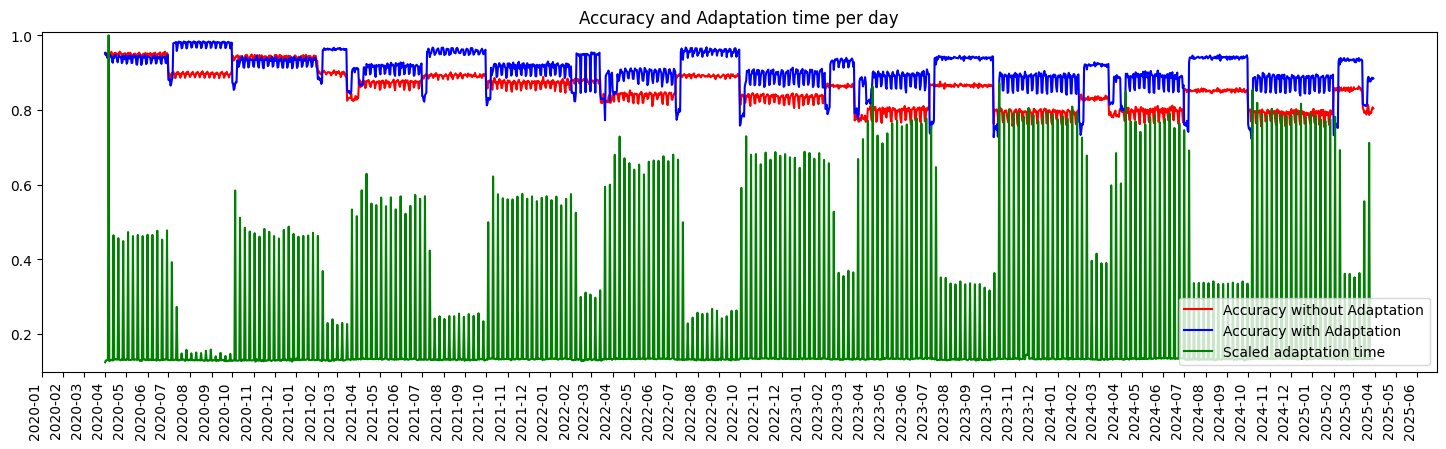

In [4]:
scaled_adaptation_times = day_scores_adaptive["adaptation_time"] / day_scores_adaptive["adaptation_time"].max()

fig, ax = plt.subplots()
ax.set_title("Accuracy and Adaptation time per day")
ax.set_ylim([0.1, 1.01])
fig.set_size_inches(18, 5, forward=True)

ax.plot(day_scores_static["average"],"r-", label="Accuracy without Adaptation")
ax.plot(day_scores_adaptive["average"], "b-", label="Accuracy with Adaptation")
ax.plot(scaled_adaptation_times, "g-",  label="Scaled adaptation time")
ax.legend(loc="lower right")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval = 1))
fig.autofmt_xdate()
plt.xticks(rotation=90) 

plt.show()

As can be seen, the accuracy patterns change significantly between semester times and vacation times. Without adaptation, the accuracy degrades over vacation times. With adaptation, the accuracy increases. 

We can also see that overall accuracy decreases as more students join the university. This is especially visible without adaptation. With adaptation, the model is able to adjust to the changing patterns, but doesn't reach the levels of the first year.

We can see weekly spikes in adaptation times that correspond to the weekly adaptation rythm. The magnitute of the spikes should be roughly proportional to how many rooms were below the 90% threshold and consequently were retrained. Adaptations are more frequent during semester times and less frequent during semester vacation times. Later in the scenario, the number of adaptations rises as the added randomness of student numbers means rooms fall below the 90% accuracy threshold more often.

## Accuracy per room.

Here we plot accuracy scores for each room. 
For each room we plot the adaptation accuracy without (left) and with (right) adaptation.

In [ ]:

fig, subplots = plt.subplots(ncols= 2,nrows= nr_rooms, figsize = (20,5*nr_rooms))

for room_index in range(nr_rooms):
    ax1 = subplots[room_index][0]
    ax1.set_title(f"Average Accuracy score of room {room_names[room_index]} per day without adaptation")
    ax1.plot(day_scores_static[room_index],"r-")
    ax1.set_ylim([0, 1.1])
    ax1.xaxis.set_major_locator(mdates.MonthLocator(interval = 3))


    ax2 = subplots[room_index][1]
    ax2.set_title(f"Average Accuracy of room {room_names[room_index]} per day with adaptation")
    ax2.plot(day_scores_adaptive[room_index],"b-")
    ax2.set_ylim([0, 1.1])
    ax2.xaxis.set_major_locator(mdates.MonthLocator(interval = 3))
    
fig.tight_layout()
fig.autofmt_xdate()
plt.xticks(rotation=90) 
plt.show()